### Import Library

In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

### Load Data Manual dan Indobert

In [2]:
MANUAL_PATH = '../../data/labeled/manual_labeling.csv'
INDOBERT_PATH = '../../data/labeled/indobert_labeled.csv'

# manual revisi memakai separator ;
df_manual = pd.read_csv(MANUAL_PATH, encoding="utf-8-sig")

# file indobert memakai separator koma
df_indobert = pd.read_csv(INDOBERT_PATH, encoding="utf-8-sig")

df_manual.columns = df_manual.columns.str.strip()
df_indobert.columns = df_indobert.columns.str.strip()

print("Data manual:", df_manual.shape)
print("Data indober:", df_indobert.shape)

print("\nKolom manual:")
print(df_manual.columns.tolist())

print("\nKolom indobert:")
print(df_indobert.columns.tolist())

Data manual: (8790, 2)
Data indober: (48546, 4)

Kolom manual:
['text', 'label']

Kolom indobert:
['text', 'original_text', 'clean_text', 'label_indobert']


### Merapihkan Nama Label

In [3]:
def normalize_label(label):
    label = str(label).strip().lower()

    mapping = {
        "negative": "negative",
        "negatif": "negative",
        "neg": "negative",

        "positive": "positive",
        "positif": "positive",
        "pos": "positive",

        "neutral": "neutral",
        "netral": "neutral",
        "neu": "neutral"
    }

    return mapping.get(label, label)


df_manual["label_manual"] = df_manual["label"].apply(normalize_label)
df_indobert["label_indobert"] = df_indobert["label_indobert"].apply(normalize_label)

print("Distribusi label manual:")
print(df_manual["label_manual"].value_counts())

print("\nDistribusi label indobert:")
print(df_indobert ["label_indobert"].value_counts())

Distribusi label manual:
label_manual
negative    6043
positive    1691
neutral     1056
Name: count, dtype: int64

Distribusi label indobert:
label_indobert
negative    27677
positive    11900
neutral      8969
Name: count, dtype: int64


### Menggabungkan data manual dengan hasil Indobert

Karena file label manual berisi 8.790 data, sedangkan Indobert berisi 48.546 data, maka bagian yang dibandingkan adalah 8.790 data pertama.

In [4]:
n_manual = len(df_manual)

df_manual_subset = df_manual.copy().reset_index(drop=True)
df_indobert_subset = df_indobert.iloc[:n_manual].copy().reset_index(drop=True)

df_svm_indobert = pd.DataFrame({
    "manual_text": df_manual_subset["text"],
    "clean_text": df_indobert_subset["clean_text"],
    "label_manual": df_manual_subset["label_manual"],
    "label_indobert": df_indobert_subset["label_indobert"]
})

df_svm_indobert["clean_text"] = df_svm_indobert["clean_text"].fillna("").astype(str)
df_svm_indobert = df_svm_indobert[df_svm_indobert["clean_text"].str.strip() != ""]

print("Jumlah data siap pakai:", len(df_svm_indobert))

df_svm_indobert.head()

Jumlah data siap pakai: 8784


,manual_text,clean_text,label_manual,label_indobert
0,adil jokowi,adil jokowi,negative,positive
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,positive
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,positive
4,lo bayar nih utang,lo bayar nih utang,negative,negative


### Menampilkan sampel data hasil penggabungan label manual dan label IndoBERT

In [5]:
df_svm_indobert[[
    "manual_text",
    "clean_text",
    "label_manual",
    "label_indobert"
]].head(20)

,manual_text,clean_text,label_manual,label_indobert
0,adil jokowi,adil jokowi,negative,positive
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,positive
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,positive
4,lo bayar nih utang,lo bayar nih utang,negative,negative
5,ijazah kamu mana wi,ijazah kamu mana wi,negative,negative
6,jangan jadi indonesia pernah tipu satu keluarg...,jangan jadi indonesia pernah tipu satu keluarg...,negative,negative
7,sir kok lebih tarik pinjam bunga lebih tinggi ...,sir kok lebih tarik pinjam bunga lebih tinggi ...,negative,negative
8,waris susah presiden sekarang pak,waris susah presiden sekarang pak,negative,negative
9,halo pak,halo pak,neutral,neutral


## Split Data

In [10]:
X = df_svm_indobert["clean_text"]

# Ground truth
y_manual = df_svm_indobert["label_manual"]

# Label training
y_indobert = df_svm_indobert["label_indobert"]

indices = np.arange(len(df_svm_indobert))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_manual
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Training menggunakan label IndoBERT
y_train = y_indobert.iloc[train_idx]

# Evaluasi menggunakan label manual
y_test = y_manual.iloc[test_idx]

print("="*60)
print("Jumlah Data")
print("="*60)
print("Train :", len(X_train))
print("Test  :", len(X_test))

print("\nDistribusi Training (Label IndoBERT)")
print(y_train.value_counts())

print("\nDistribusi Testing (Ground Truth Manual)")
print(y_test.value_counts())



Jumlah Data
Train : 7027
Test  : 1757

Distribusi Training (Label IndoBERT)
label_indobert
negative    4193
positive    1815
neutral     1019
Name: count, dtype: int64

Distribusi Testing (Ground Truth Manual)
label_manual
negative    1208
positive     338
neutral      211
Name: count, dtype: int64


## Pipeline

In [ ]:
pipeline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1,2),
            min_df=2,
            sublinear_tf=True
        )
    ),

    (
        "oversample",
        RandomOverSampler(
            random_state=42
        )
    ),

    (
        "svm",
        LinearSVC(
            random_state=42
        )
    )

])

# GRID SEARCH
param_grid = {

    "svm__C":[
        0.01,
        0.1,
        1,
        10,
        100
    ]

}

grid = GridSearchCV(

    estimator=pipeline,

    param_grid=param_grid,

    cv=5,

    scoring="f1_macro",

    n_jobs=-1

)

print("\nTraining model ...")

grid.fit(
    X_train,
    y_train
)

print("\nTraining selesai")

print("\nBest Parameter")
print(grid.best_params_)

print("\nBest Cross Validation Score")
print(grid.best_score_)

# MODEL TERBAIK
svm_indobert_model = grid.best_estimator_

# PREDIKSI
y_pred = svm_indobert_model.predict(
    X_test
)


Training model ...

Training selesai

Best Parameter
{'svm__C': 0.1}

Best Cross Validation Score
0.6769959659942442


## Evaluasi



HASIL EVALUASI SVM LABEL INDOBERT (BALANCED DATASET)
Accuracy            : 0.6363
Macro Precision     : 0.5242
Macro Recall        : 0.5594
Macro F1-score      : 0.5305

Weighted Precision  : 0.6994
Weighted Recall     : 0.6363
Weighted F1-score   : 0.6599

Classification Report

              precision    recall  f1-score   support

    negative       0.84      0.70      0.76      1208
     neutral       0.24      0.43      0.31       211
    positive       0.49      0.56      0.52       338

    accuracy                           0.64      1757
   macro avg       0.52      0.56      0.53      1757
weighted avg       0.70      0.64      0.66      1757



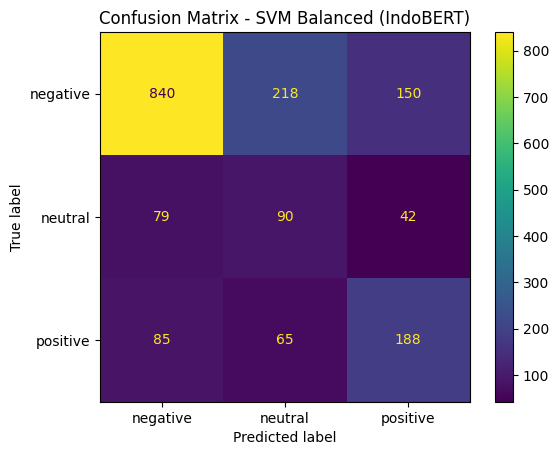

In [12]:
labels_order = [
    "negative",
    "neutral",
    "positive"
]

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision_macro = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\n")
print("="*70)
print("HASIL EVALUASI SVM LABEL INDOBERT (BALANCED DATASET)")
print("="*70)

print(f"Accuracy            : {accuracy:.4f}")
print(f"Macro Precision     : {precision_macro:.4f}")
print(f"Macro Recall        : {recall_macro:.4f}")
print(f"Macro F1-score      : {f1_macro:.4f}")

print()

print(f"Weighted Precision  : {precision_weighted:.4f}")
print(f"Weighted Recall     : {recall_weighted:.4f}")
print(f"Weighted F1-score   : {f1_weighted:.4f}")

print("\nClassification Report\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=labels_order,
        zero_division=0
    )
)

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

cm = confusion_matrix(

    y_test,

    y_pred,

    labels=labels_order

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=labels_order

)

disp.plot(values_format="d")

plt.title(
    "Confusion Matrix - SVM Balanced (IndoBERT)"
)

plt.show()



## MELIHAT DISTRIBUSI DATA SETELAH OVERSAMPLING

In [14]:
print("="*60)
print("DISTRIBUSI DATA TRAINING")
print("="*60)

print("\nSebelum Oversampling")
print(y_train.value_counts())

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(
    X_train
)

ros = RandomOverSampler(
    random_state=42
)

X_balance, y_balance = ros.fit_resample(
    X_train_tfidf,
    y_train
)

print("\nSesudah Oversampling")
print(pd.Series(y_balance).value_counts())

DISTRIBUSI DATA TRAINING

Sebelum Oversampling
label_indobert
negative    4193
positive    1815
neutral     1019
Name: count, dtype: int64

Sesudah Oversampling
label_indobert
positive    4193
neutral     4193
negative    4193
Name: count, dtype: int64
